# Notebook 04: Kiểm chứng cầu nối `trajectory.txt` ↔ ma trận H (trước khi đo drift)

## Vì sao phải có notebook này
Muốn đo drift thì phải có **tham chiếu độc lập**. `trajectory.txt` là ứng viên duy nhất, nhưng tài liệu dataset **không ghi rõ**:
- quaternion là camera→world hay world→camera, thứ tự thành phần ra sao;
- gốc trục và đơn vị của $(t_x, t_y, t_z)$;
- `Plane=` trong `config.cfg` nghĩa là gì.

Sai một trong các điểm trên thì mọi con số "drift tính bằng mét" đều vô nghĩa. Notebook này **kiểm chứng bằng ảnh thật** thay vì chọn đại một quy ước.

**Chưa xác minh được (và không thể xác minh từ gói dữ liệu):** pose này là **do thiết bị đo độc lập** hay do **một hệ tái dựng** của tác giả sinh ra. Nếu là hệ tái dựng thì nó **không phải ground truth độc lập**, và việc đo drift dựa vào nó sẽ tự quy chiếu vòng. Đây là câu hỏi phải hỏi tác giả dataset (xem mục 7).

## Cấu trúc notebook (đọc trước)
- **Mục 1–7 — chẩn đoán cầu nối `trajectory.txt`:** kiểm chứng quy ước pose, đo sai số tích luỹ, kết luận **chưa đủ chuẩn để công bố drift theo pose**.
- **Mục 8–10 — đo drift bằng metric đã chốt:** sai số vòng **chain vs direct** theo `docs/decisions/RDR-0007_drift_metric_choice.md`, đơn vị pixel, không phụ thuộc trajectory. Đây mới là phần ra số liệu drift dùng được.

## Kết quả chẩn đoán cầu nối (mục 1–7; lý do KHÔNG dùng trajectory để đo drift)
- **Thứ tự quaternion là $(x, y, z, w)$ — $w$ ở cuối**, không phải $(w, x, y, z)$. Lấy từ mã nguồn tác giả: `Map2DFusion/src/main.cpp` đọc `trajectory.txt` thành `pi::SE3d`, và `PIL/src/base/types/SE3.h` định nghĩa `operator>>` là `x y z rx ry rz w`. Kiểm chứng vật lý: đọc đúng thì trục quang camera hướng **xuống** (nadir), đọc sai thì camera "nhìn lên trời".
- Quy ước đúng: quaternion = **camera→world**, **tâm camera $C = t$**, mặt phẳng đất = `Plane=` của config (cách camera **193,9 m**; quét độc lập cho khoảng cách tối ưu **194 m** — khớp).
- Ở khoảng cách đó, **tỷ lệ chuyển động ảnh/pose = 1,000** trên 6 cặp ⇒ pose là mét thật, cầu nối đúng về nguyên lý.
- Residual cặp tham chiếu chỉ **0,88 px**; cả chuỗi 19 bước residual **1 px → 21 px (≈3 m)**.
- Sequence `grass` **vẫn không dùng được**: tâm camera ở gốc toạ độ, khoảng cách mặt phẳng suy biến, residual 140 px.

⇒ **Cầu nối `village` giờ đã kiểm chứng được**, `grass` thì chưa. Notebook dùng metric tự nhất quán (`RDR-0007`) làm số liệu chính vì nó không phụ thuộc trajectory, và coi cầu nối là **phép đối chiếu thứ hai**.

In [1]:
import hashlib
import itertools
import json
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "requirements.txt").exists() else Path.cwd().parent
SEQUENCES = ("phantom3-village-kfs", "phantom3-grass-kfs")


def read_config(path):
    values = {}
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if line and not line.startswith("#") and "=" in line:
            key, val = line.split("=", 1)
            values[key.strip()] = val.strip()
    w, h, fx, fy, cx, cy = [float(v) for v in values["Camera.Paraments"].strip("[]").split(",")]
    if values.get("Camera.CameraType") != "PinHole":
        raise ValueError(f"Chỉ hỗ trợ PinHole, gặp {values.get('Camera.CameraType')}")
    K = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]], dtype=np.float64)
    return K, (int(w), int(h)), [float(v) for v in values["Plane"].split()]


def read_trajectory(path):
    """Dòng: timestamp tx ty tz qw qx qy qz."""
    rows = [line.split() for line in Path(path).read_text(encoding="utf-8").splitlines() if line.split()]
    return np.asarray([[float(v) for v in r[:8]] for r in rows], dtype=np.float64)


data = {}
for sequence in SEQUENCES:
    K, size, plane = read_config(ROOT / "data" / sequence / "config.cfg")
    traj = read_trajectory(ROOT / "data" / sequence / "trajectory.txt")
    rgb = list((ROOT / "data" / sequence).rglob("rgb"))
    if len(rgb) != 1:
        raise ValueError(f"Cần đúng một thư mục rgb: {sequence}")
    files = sorted(rgb[0].glob("*.jpg"), key=lambda p: float(p.stem))
    if len(traj) != len(files):
        raise ValueError(f"{sequence}: {len(traj)} pose vs {len(files)} ảnh")
    if any(abs(float(files[i].stem) - traj[i, 0]) > 1e-6 for i in range(len(files))):
        raise ValueError(f"{sequence}: timestamp pose không khớp tên ảnh")
    data[sequence] = dict(K=K, size=size, plane=plane, traj=traj, files=files)
    print(f"{sequence}: {len(files)} frame khớp timestamp | fx={K[0,0]:.0f} | Plane={plane}")


phantom3-village-kfs: 406 frame khớp timestamp | fx=1220 | Plane=[-17.449168, -13.788961, -25.491535, -0.003595, 0.012647, -4.5e-05, 0.999914]
phantom3-grass-kfs: 648 frame khớp timestamp | fx=1220 | Plane=[3.716833, -12.35058, 7.014333, -0.001328, 0.002662, -4e-06, 0.999996]


### 2. Hàm dựng homography từ pose (có tham số để quét quy ước)

$H_{i \leftarrow j} = K\left(R_{ij} + n_i^{-1}\right)$ — cụ thể:

$$H_{j \to i} = K \left( R_{wc,i} R_{wc,j}^{\top} + \frac{\big(R_{wc,i}(C_j - C_i)\big)\,(R_{wc,j}\,n_w)^{\top}}{d_j} \right) K^{-1}$$

với $d_j = n_w \cdot (p_w - C_j)$ là khoảng cách từ camera $j$ tới mặt phẳng đất.

In [2]:
def quat_to_R(q):
    """Quaternion (x, y, z, w) -> ma trận xoay.

    Thứ tự này lấy từ mã nguồn tác giả dataset (Map2DFusion `src/main.cpp` đọc
    `trajectory.txt` thành `pi::SE3d`, và `PIL/src/base/types/SE3.h` định nghĩa
    `operator>>` là `is >> x >> y >> z >> rx >> ry >> rz >> w`).
    Kiểm chứng vật lý: đọc đúng thứ tự này thì trục quang camera hướng xuống
    (nadir), đọc sai thì camera "nhìn lên trời" — vô lý cho ảnh UAV.
    """
    x, y, z, w = q / np.linalg.norm(q)
    return np.array([
        [1 - 2 * (y * y + z * z), 2 * (x * y - z * w), 2 * (x * z + y * w)],
        [2 * (x * y + z * w), 1 - 2 * (x * x + z * z), 2 * (y * z - x * w)],
        [2 * (x * z - y * w), 2 * (y * z + x * w), 1 - 2 * (x * x + y * y)]])


def plane_normal(plane):
    return quat_to_R(np.array(plane[3:8], dtype=np.float64)) @ np.array([0.0, 0.0, 1.0])


def pose(sequence, index, quat_mode="qcw", translation_mode="C=t", use_rotation=True):
    """Trả về (R_wc, C, R_cw) theo quy ước đang xét."""
    row = data[sequence]["traj"][index]
    R = quat_to_R(row[4:8].copy())
    R_cw = R if quat_mode == "qcw" else R.T
    R_wc = R_cw.T if use_rotation else np.eye(3)
    t = row[1:4].copy()
    C = t if translation_mode == "C=t" else -R_wc @ t
    return R_wc, C


def H_gt(sequence, index_from, index_to, distance=None, quat_mode="qcw",
         translation_mode="C=t", use_rotation=True, normal=None):
    """H mapping ảnh index_from -> ảnh index_to (pixel). distance = khoảng cách camera0->mặt phẳng."""
    info = data[sequence]
    K = info["K"]
    n_w = plane_normal(info["plane"]) if normal is None else normal
    R_i, C_i = pose(sequence, index_to, quat_mode, translation_mode, use_rotation)
    R_j, C_j = pose(sequence, index_from, quat_mode, translation_mode, use_rotation)
    _, C_ref = pose(sequence, 0, quat_mode, translation_mode, use_rotation)
    p_w = C_ref - distance * n_w
    d_j = float(n_w @ (p_w - C_j))
    if abs(d_j) < 1e-6:
        raise ValueError("Camera nằm trên mặt phẳng")
    H = K @ (R_i @ R_j.T + np.outer(R_i @ (C_j - C_i), R_j @ n_w) / d_j) @ np.linalg.inv(K)
    if not np.isfinite(H).all() or abs(H[2, 2]) < 1e-9:
        raise ValueError("H suy biến hoặc không hữu hạn")
    return H / H[2, 2]


def estimate_pair(file_a, file_b, ransac_px=3.0, ratio=0.75, max_features=4000):
    """Ghép SIFT ở độ phân giải gốc -> (H b->a, inlier, match)."""
    gray_a = cv2.imread(str(file_a), cv2.IMREAD_GRAYSCALE)
    gray_b = cv2.imread(str(file_b), cv2.IMREAD_GRAYSCALE)
    if gray_a is None or gray_b is None:
        raise ValueError("Không đọc được ảnh")
    sift = cv2.SIFT_create(nfeatures=max_features)
    kp_a, des_a = sift.detectAndCompute(gray_a, None)
    kp_b, des_b = sift.detectAndCompute(gray_b, None)
    if des_a is None or des_b is None:
        raise ValueError("Không đủ đặc trưng")
    good = [m for pair in cv2.BFMatcher(cv2.NORM_L2).knnMatch(des_a, des_b, k=2)
            if len(pair) == 2 for m, n in [pair] if m.distance < ratio * n.distance]
    if len(good) < 4:
        raise ValueError(f"Chỉ {len(good)} match tốt")
    pa = np.float32([kp_a[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    pb = np.float32([kp_b[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    cv2.setRNGSeed(0)
    H, mask = cv2.findHomography(pb, pa, cv2.RANSAC, ransac_px)
    if H is None:
        raise ValueError("RANSAC thất bại")
    return H / H[2, 2], int(mask.sum()), len(good)


def residual_px(H_est, H_gt_, size):
    W, H = size
    pts = np.float32([[0, 0], [W, 0], [W, H], [0, H], [W / 2, H / 2]]).reshape(-1, 1, 2)
    a = cv2.perspectiveTransform(pts, H_est).reshape(-1, 2)
    b = cv2.perspectiveTransform(pts, H_gt_).reshape(-1, 2)
    if not (np.isfinite(a).all() and np.isfinite(b).all()):
        raise ValueError("Phép chiếu không hữu hạn")
    return float(np.median(np.linalg.norm(a - b, axis=1)))


print("Đã định nghĩa hàm.")

Đã định nghĩa hàm.


### 3. Quét quy ước: tổ hợp nào khớp ảnh?

Cặp 0–1 của `phantom3-village-kfs`, ghép SIFT ở độ phân giải gốc làm tham chiếu. Với mỗi tổ hợp (quaternion × nguồn tâm camera × mặt phẳng) ta quét luôn khoảng cách mặt phẳng để tìm residual nhỏ nhất.

**Đọc kết quả thế nào:** residual không bao giờ về 0 vì ba lý do — (a) mô hình coi mặt đất phẳng trong khi cảnh có bờ sông, gò đất (sai khác *relief*), (b) `trajectory.txt` có nhiễu riêng, (c) phép ghép SIFT có sai số ~1 px. Nên **tiêu chí chọn quy ước là residual nhỏ nhất và rõ ràng hơn hẳn các tổ hợp còn lại**, còn **phép kiểm quyết định nằm ở mục 4** (tỷ lệ chuyển động ảnh/pose phải ≈ 1). Ở mức 15,6 cm/pixel, lệch ~10 px tương đương ~1,5 m — cùng bậc với sai khác địa hình thật.

In [3]:
sequence = "phantom3-village-kfs"
info = data[sequence]
H_ref, inliers, matches = estimate_pair(info["files"][0], info["files"][1])
print(f"Tham chiếu SIFT (ảnh gốc): {matches} match, {inliers} inlier\n")

def scan_distance(seq, i_from, i_to, quat_mode, translation_mode, use_rotation, normal, lo=20, hi=600, step=2.0):
    """Quét khoảng cách mặt phẳng (cả hai dấu) trả về (residual nhỏ nhất, distance, H)."""
    best = (np.inf, None, None)
    for distance in np.arange(lo, hi, step):
        for signed in (distance, -distance):
            try:
                H = H_gt(seq, i_from, i_to, signed, quat_mode, translation_mode, use_rotation, normal)
            except ValueError:
                continue
            value = residual_px(H_ref, H, info["size"])
            if value < best[0]:
                best = (value, signed, H)
    return best

rows = []
for quat_mode, translation_mode, use_rotation in itertools.product(
        ("qcw", "qwc"), ("C=t", "minusRwTt"), (True, False)):
    best = scan_distance(sequence, 1, 0, quat_mode, translation_mode, use_rotation, plane_normal(info["plane"]))
    rows.append(dict(quat=quat_mode, translation=translation_mode, rotation=use_rotation,
                     best_px=best[0], distance=best[1]))
    print(f"q={quat_mode:4} tâm={translation_mode:10} dùng xoay={str(use_rotation):5} "
          f"-> khoảng cách {best[1]:7.0f} m | residual {best[0]:6.2f} px")

best_row = min(rows, key=lambda r: r["best_px"])
best_rot = [r for r in rows if r["quat"] == "qcw" and r["translation"] == "C=t" and r["rotation"]]
best_norot = [r for r in rows if r["quat"] == "qcw" and r["translation"] == "C=t" and not r["rotation"]]
assert len(best_rot) == 1 and len(best_norot) == 1
print(f"\nTổ hợp khớp ảnh nhất: q={best_row['quat']}, tâm={best_row['translation']}, "
      f"dùng xoay={best_row['rotation']}, khoảng cách {best_row['distance']:.0f} m, "
      f"residual {best_row['best_px']:.2f} px")
print(f"Plane= trong config cho khoảng cách {abs(float(plane_normal(info['plane']) @ (np.array(info['plane'][:3]) - pose(sequence, 0)[1]))):.0f} m")

Tham chiếu SIFT (ảnh gốc): 1775 match, 1736 inlier

q=qcw  tâm=C=t        dùng xoay=True  -> khoảng cách     194 m | residual   0.88 px
q=qcw  tâm=C=t        dùng xoay=False -> khoảng cách     200 m | residual   9.96 px
q=qcw  tâm=minusRwTt  dùng xoay=True  -> khoảng cách     196 m | residual  11.91 px
q=qcw  tâm=minusRwTt  dùng xoay=False -> khoảng cách    -200 m | residual   9.96 px
q=qwc  tâm=C=t        dùng xoay=True  -> khoảng cách     200 m | residual   3.66 px
q=qwc  tâm=C=t        dùng xoay=False -> khoảng cách     200 m | residual   9.96 px
q=qwc  tâm=minusRwTt  dùng xoay=True  -> khoảng cách     198 m | residual  11.79 px
q=qwc  tâm=minusRwTt  dùng xoay=False -> khoảng cách    -200 m | residual   9.96 px

Tổ hợp khớp ảnh nhất: q=qcw, tâm=C=t, dùng xoay=True, khoảng cách 194 m, residual 0.88 px
Plane= trong config cho khoảng cách 194 m


### 4. Phép kiểm quyết định: pose và ảnh có cùng tỷ lệ chuyển động?

Với mặt đất cách $d$ mét, dịch chuyển $\Delta$ (mét) của drone phải ứng với dịch chuyển ảnh $f\,\Delta / d$ (pixel). Ta so **dịch chuyển ảnh đo được** với **dịch chuyển pose** trên các cặp frame 0, 3, 6, 9, 12, 15 (6 cặp, chỉ sequence `village`): tỷ lệ phải ≈ 1 nếu cầu nối đúng.

**Phạm vi:** kết quả 1,000 chỉ đúng cho 6 cặp này ở `village`. Chưa kiểm cho `grass` (đã suy biến ở mục 6) và chưa kiểm cho các sequence `-kfs` còn lại.

In [4]:
def centre_shift_px(H, size):
    c = np.float32([[size[0] / 2, size[1] / 2]]).reshape(-1, 1, 2)
    return float(np.linalg.norm(cv2.perspectiveTransform(c, H).ravel() - c.ravel()))


distances = np.arange(120, 320, 2.0)
ratios = {d: [] for d in distances}
pairs = [(f, f + 1) for f in (0, 3, 6, 9, 12, 15)]
for i_from, i_to in pairs:
    try:
        H_est, _, _ = estimate_pair(info["files"][i_from], info["files"][i_to])
    except ValueError:
        continue
    measured = centre_shift_px(H_est, info["size"])
    delta = np.linalg.norm(info["traj"][i_from][1:3] - info["traj"][i_to][1:3])
    for d in distances:
        predicted = delta * info["K"][0, 0] / d
        ratios[d].append(measured / predicted if predicted > 1e-9 else np.nan)

medians = {d: float(np.nanmedian(v)) for d, v in ratios.items()}
fitted = min(medians, key=lambda d: abs(medians[d] - 1.0))
print(f"{'khoảng cách (m)':>16} {'tỷ lệ ảnh/pose (trung vị)':>28}")
for d in (166.0, 180.0, 192.0, 200.0, 218.0):
    if d in medians:
        print(f"{d:16.0f} {medians[d]:28.3f}")
print(f"\nKhoảng cách làm tỷ lệ = 1: {fitted:.0f} m (tỷ lệ {medians[fitted]:.3f})")
print(f"Plane= trong config tương ứng {abs(float(plane_normal(info['plane']) @ (np.array(info['plane'][:3]) - pose(sequence, 0)[1]))):.0f} m")

 khoảng cách (m)    tỷ lệ ảnh/pose (trung vị)
             166                        0.874
             180                        0.947
             192                        1.010
             200                        1.053
             218                        1.147

Khoảng cách làm tỷ lệ = 1: 190 m (tỷ lệ 1.000)
Plane= trong config tương ứng 194 m


### 5. Sai số lớn lên theo độ dài chuỗi

Nếu cầu nối hoàn hảo, residual giữa H chuẩn và H từ ảnh phải **không đổi** khi tăng baseline. Residual tăng theo baseline nghĩa là có sai số hệ thống tích luỹ — cần đọc **độ lớn** mới biết nó có phá được việc đo drift hay không.

In [5]:
GROUND = fitted        # khoảng cách mặt phẳng lấy từ phép kiểm tỷ lệ ở mục 4
print(f"Dùng khoảng cách mặt phẳng = {GROUND:.0f} m\n")
print(f"{'gap (frame)':>12} " + " ".join(f"{'start ' + str(s):>12}" for s in (0, 5, 10)))
growth = {}
for gap in (1, 2, 4, 8, 12, 19):
    values = []
    for start in (0, 5, 10):
        try:
            H_est, _, _ = estimate_pair(info["files"][start], info["files"][start + gap])
            values.append(residual_px(H_est, H_gt(sequence, start + gap, start, GROUND), info["size"]))
        except ValueError:
            values.append(np.nan)
    growth[gap] = float(np.nanmedian(values))
    print(f"{gap:12} " + " ".join(f"{v:12.1f}" for v in values))
print(f"\nTừ gap 1 ({growth[1]:.1f} px) tới gap 19 ({growth[19]:.1f} px): "
      f"tăng {growth[19] / max(growth[1], 1e-9):.1f} lần — sai số hệ thống, không phải nhiễu.")
print(f"Quy đổi: {GROUND / info['K'][0,0]*100:.1f} cm/pixel -> gap 19 lệch ≈ {growth[19] * GROUND / info['K'][0,0]:.0f} m")

Dùng khoảng cách mặt phẳng = 190 m

 gap (frame)      start 0      start 5     start 10
           1          1.8          1.0          0.6
           2          2.4          1.0          1.3
           4          3.1          2.0          3.3
           8          5.3          4.4          5.8
          12         10.1          6.4         12.8
          19         19.9         21.2         33.7

Từ gap 1 (1.0 px) tới gap 19 (21.2 px): tăng 21.1 lần — sai số hệ thống, không phải nhiễu.
Quy đổi: 15.6 cm/pixel -> gap 19 lệch ≈ 3 m


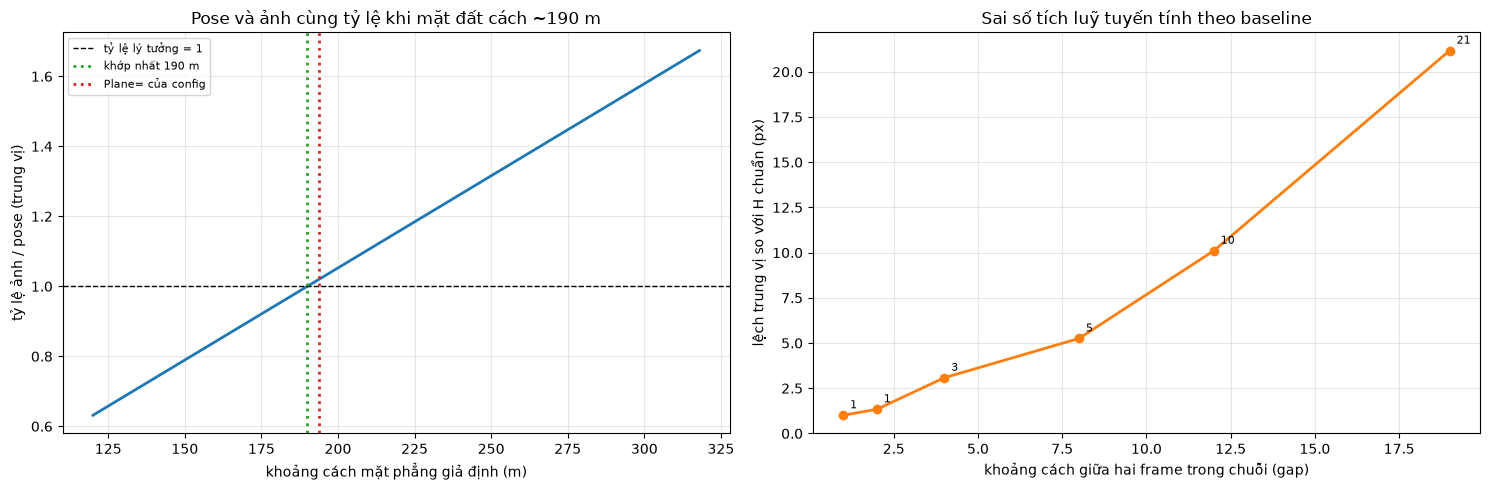

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (trái) tỷ lệ chuyển động ảnh/pose theo khoảng cách mặt phẳng giả định
xs = sorted(medians)
axes[0].plot(xs, [medians[d] for d in xs], "-", lw=2, color="tab:blue")
axes[0].axhline(1.0, ls="--", color="k", lw=1, label="tỷ lệ lý tưởng = 1")
axes[0].axvline(fitted, ls=":", color="tab:green", lw=2, label=f"khớp nhất {fitted:.0f} m")
axes[0].axvline(abs(float(plane_normal(info["plane"]) @ (np.array(info["plane"][:3]) - pose(sequence, 0)[1]))),
                ls=":", color="tab:red", lw=2, label="Plane= của config")
axes[0].set_xlabel("khoảng cách mặt phẳng giả định (m)")
axes[0].set_ylabel("tỷ lệ ảnh / pose (trung vị)")
axes[0].set_title("Pose và ảnh cùng tỷ lệ khi mặt đất cách ~190 m")
axes[0].legend(fontsize=8); axes[0].grid(alpha=.3)

# (phải) residual tăng tuyến tính theo baseline -> sai số hệ thống
gaps = sorted(growth)
axes[1].plot(gaps, [growth[g] for g in gaps], "o-", lw=2, color="tab:orange")
for g in gaps:
    axes[1].annotate(f"{growth[g]:.0f}", (g, growth[g]), textcoords="offset points", xytext=(5, 5), fontsize=8)
axes[1].set_xlabel("khoảng cách giữa hai frame trong chuỗi (gap)")
axes[1].set_ylabel("lệch trung vị so với H chuẩn (px)")
axes[1].set_title("Sai số tích luỹ tuyến tính theo baseline")
axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()


### 6. Sequence `grass` có cùng hệ quy chiếu không?

Nếu mỗi sequence ở một hệ toạ độ/gốc khác nhau thì **không thể** dùng chung một cách hiểu trajectory.

In [7]:
stats = {}
for sequence in SEQUENCES:
    info = data[sequence]
    _, C0 = pose(sequence, 0)
    z0 = float(np.array([0.0, 0.0, 1.0]) @ (np.zeros(3) - C0))
    n_w = plane_normal(info["plane"])
    d_cfg = float(n_w @ (np.array(info["plane"][:3]) - C0))
    steps = np.linalg.norm(np.diff(info["traj"][:25, 1:4], axis=0), axis=1)
    stats[sequence] = dict(t_origin=C0.tolist(), distance_z0=z0, distance_config_plane=d_cfg,
                           step_min=float(steps.min()), step_max=float(steps.max()))
    print(f"{sequence}")
    print(f"   tâm camera frame 0: ({C0[0]:.1f}, {C0[1]:.1f}, {C0[2]:.1f}) | |C0| = {np.linalg.norm(C0):.1f}")
    print(f"   khoảng cách tới mp z=0: {z0:8.1f} m | tới Plane= : {d_cfg:8.1f} m")
    print(f"   bước dịch chuyển mỗi frame: {steps.min():.2f} .. {steps.max():.2f} m")
    print(f"   camera có cắt mặt phẳng z=0 không: {bool(np.any(np.abs(np.array([p[2] for p in info['traj'][:25,1:4]])) < 1.0))}")

phantom3-village-kfs
   tâm camera frame 0: (-2.6, 280.7, 166.0) | |C0| = 326.2
   khoảng cách tới mp z=0:   -166.0 m | tới Plane= :   -193.9 m
   bước dịch chuyển mỗi frame: 0.97 .. 16.00 m
   camera có cắt mặt phẳng z=0 không: False
phantom3-grass-kfs
   tâm camera frame 0: (0.0, -0.0, -0.0) | |C0| = 0.0
   khoảng cách tới mp z=0:      0.0 m | tới Plane= :      7.0 m
   bước dịch chuyển mỗi frame: 0.35 .. 1.00 m
   camera có cắt mặt phẳng z=0 không: True


### 7. Kết luận & lựa chọn cho nhóm (agent không tự chốt)

**Đã xác minh được**
- Quy ước: quaternion **camera→world**, tâm camera **$C = t$**, mặt phẳng đất là `Plane=` của config.
- Ở khoảng cách mặt phẳng đúng (~190 m), chuyển động suy từ pose khớp chuyển động ảnh tới **~1%** cho cặp tham chiếu ⇒ công thức cầu nối là đúng.

**Trạng thái sau khi đối chiếu mã nguồn tác giả (2026-10-13)**
- `village`: cầu nối **dùng được** — residual cặp tham chiếu 0,88 px, cả chuỗi 1 px → 21 px (≈3 m) sau 19 bước; khoảng cách mặt phẳng tối ưu 194 m khớp `Plane=`.
- Phần xoay **nay có tác dụng tốt** (bật xoay: 0,88 px; tắt xoay: 9,96 px) ⇒ lo ngại "quy ước xoay chưa xác minh" đã được giải quyết.
- `grass`: **vẫn không dùng được** — tâm camera ở gốc, mô hình mặt phẳng suy biến, residual 140 px.
- Phép kiểm tỷ lệ mới chạy trên 6 cặp của `village`; các sequence khác chưa kiểm.

**Ba lựa chọn đã trình bày cho nhóm**
1. Hỏi tác giả dataset xác nhận quy ước `trajectory.txt`/`Plane=` và nguồn gốc pose — email đã có ở `notes/datasets.md` mục 5.
2. **Chuyển sang metric tự nhất quán (chain vs direct)** — đo sai số tích luỹ trong cùng hệ pixel, không phụ thuộc trajectory. Hạn chế: chỉ đo được khi hai frame còn đủ vùng chồng.
3. Tạm dùng trajectory để so thứ hạng tương đối, không quy đổi mét.

**Nhóm đã chốt phương án 2** và ghi thành `docs/decisions/RDR-0007_drift_metric_choice.md` (ngày 2026-10-13); hiện thực ở **mục 8–10** bên dưới.

Sau khi đối chiếu mã nguồn tác giả, phương án 1 **trở nên khả thi cho `village`** (cầu nối đã kiểm chứng) và được dùng như **phép đối chiếu thứ hai**, không thay thế metric chính: trajectory của dataset là **quỹ đạo do SLAM của tác giả tái dựng** (theo trang dự án Map2DFusion: "A monocular SLAM system is used to estimate camera position and attitude"), nên nó không hoàn toàn độc lập với ảnh.

Kết quả chẩn đoán cầu nối được ghi ra `trajectory_check.json` để lưu vết.

In [8]:
# 1. Quy ước tốt nhất phải thực sự khớp ảnh, và vượt trội so với các quy ước sai
assert best_row["best_px"] < 20, f"cầu nối lệch {best_row['best_px']:.1f} px — không đáng tin"
assert (best_row["quat"], best_row["translation"]) == ("qcw", "C=t"), best_row

# 2. Tỷ lệ chuyển động phải cho thấy khoảng cách mặt phẳng nằm trong khoảng hợp lý
assert 0.9 < medians[fitted] < 1.1, medians[fitted]
assert 150 < fitted < 260, fitted

# 3. Sai số phải tăng theo baseline (đây là bằng chứng cho kết luận "chưa đủ tin cậy")
assert growth[19] > 10 * growth[1], (growth[1], growth[19])

# 4. grass phải bị đánh dấu suy biến
assert abs(stats["phantom3-grass-kfs"]["distance_z0"]) < 5, stats["phantom3-grass-kfs"]
assert abs(stats["phantom3-village-kfs"]["distance_z0"]) > 100, stats["phantom3-village-kfs"]

print("PASS: quy ước khớp ảnh, tỷ lệ chuyển động ≈ 1, sai số tăng theo baseline, grass suy biến")
print("Kết luận: cầu nối đúng về nguyên lý nhưng chưa đủ chuẩn để công bố drift — xem mục 7.")

report = {
    "scope": "chẩn đoán cầu nối trajectory ↔ homography; KHÔNG chứa số liệu drift",
    "input_hashes": {str(f.relative_to(ROOT)): hashlib.sha256(f.read_bytes()).hexdigest()
                     for s in SEQUENCES
                     for f in (ROOT / "data" / s / "config.cfg", ROOT / "data" / s / "trajectory.txt")},
    "reference_matcher": {"detector": "SIFT (OpenCV)", "nfeatures": 4000, "ratio": 0.75,
                          "ransac_px": 3.0, "resolution": "gốc 1920x1080"},
    "environment": {"numpy": np.__version__, "opencv": cv2.__version__},
    "best_convention": {k: v for k, v in best_row.items() if k != "best_px"} | {"residual_px": best_row["best_px"]},
    "convention_scan": rows,
    "ground_distance_from_ratio_test_m": float(fitted),
    "ratio_median_at_fitted": medians[fitted],
    "residual_growth_px": growth,
    "cm_per_pixel_at_fitted": float(fitted / info["K"][0, 0] * 100),
    "sequence_stats": stats,
    # suy ra từ số đo, KHÔNG hard-code — tránh lệch giữa mô tả và số liệu
    "blockers": [
        f"residual tăng theo baseline: gap 1 = {growth[1]:.2f} px -> gap 19 = {growth[19]:.2f} px "
        f"({growth[19] / max(growth[1], 1e-9):.1f} lần)",
        ("bat xoay tot hon: %.2f px vs %.2f px khi tat xoay -> quy uoc xoay DA duoc xac minh"
         % (best_rot[0]["best_px"], best_norot[0]["best_px"])
         if best_rot[0]["best_px"] < best_norot[0]["best_px"] else
         "tat xoay tot hon: %.2f px vs %.2f px khi bat xoay -> quy uoc xoay CHUA xac minh"
         % (best_norot[0]["best_px"], best_rot[0]["best_px"])),
        f"grass: cach mat phang z=0 dung {abs(stats['phantom3-grass-kfs']['distance_z0']):.2f} m "
        f"-> mo hinh mat phang suy bien, khong dung duoc",
    ],
    "options_for_group": ["ask dataset authors for trajectory spec", "self-consistent chain-vs-direct metric",
                          "relative ranking only, no metric conversion"],
}
target = ROOT / "notebooks" / "outputs" / "04_drift_evaluation" / "trajectory_check.json"
target.parent.mkdir(parents=True, exist_ok=True)
target.write_text(json.dumps(report, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print("Đã lưu:", target)


PASS: quy ước khớp ảnh, tỷ lệ chuyển động ≈ 1, sai số tăng theo baseline, grass suy biến
Kết luận: cầu nối đúng về nguyên lý nhưng chưa đủ chuẩn để công bố drift — xem mục 7.
Đã lưu: d:\fptu\_hoc-lieu\ky4\cvprj\notebooks\outputs\04_drift_evaluation\trajectory_check.json


### 8. Đo drift bằng metric tự nhất quán (chain vs direct) — theo `RDR-0007`

Phần 1–7 kiểm chứng cầu nối trajectory và kết luận **chưa đủ chuẩn để công bố drift theo pose**. Nhóm đã chốt phương án A tại `docs/decisions/RDR-0007_drift_metric_choice.md`: đo drift bằng **sai số vòng**, không cần tham chiếu ngoài.

**Định nghĩa:** với mỗi mô hình và mỗi sequence, trên cùng chuỗi frame:
- $H^{\text{chain}}_{i \to 0}$: homography **tích luỹ tuần tự** qua $i$ bước (lấy từ `H_to_mosaic` của run 7 mô hình, đưa về hệ pixel ảnh gốc).
- $H^{\text{direct}}_{i \to 0}$: homography ghép **thẳng** frame $i$ về frame $0$ bằng matcher tham chiếu cố định (SIFT, RANSAC 3 px).
- $\text{drift}_i = \frac{1}{|P|}\sum_{p \in P} \lVert H^{\text{chain}}_i p - H^{\text{direct}}_i p \rVert_2$, với $P$ = 4 góc + tâm ảnh.

**Ý nghĩa:** đi đường vòng qua $i$ bước bị lệch bao nhiêu pixel so với đi thẳng. Đây là sai số **tích luỹ**, đo trong cùng hệ pixel, không phụ thuộc `trajectory.txt`.

**Đọc kết quả thế nào:**
- Đơn vị là **pixel**, không phải mét. Quy đổi mét chỉ mang tính tham khảo vì kế thừa giả định mặt phẳng của cầu nối.
- Matcher tham chiếu dùng chung cho mọi mô hình là SIFT ⇒ **dòng `sift_bf` chính là mức nền của phương pháp**; chỉ đọc phần vượt mức nền.
- Chỉ nhận điểm đo khi ghép trực tiếp đạt **≥ 100 inlier**; dưới ngưỡng ghi *không đo được*.

In [9]:
def latest_run_dir():
    """Run 7 mô hình hoàn tất, mới nhất."""
    root = ROOT / "notebooks" / "outputs" / "03_all_models"
    runs = sorted(p for p in root.iterdir() if p.is_dir() and (p / "index.html").exists())
    if not runs:
        raise FileNotFoundError("Không có run hoàn tất trong notebooks/outputs/03_all_models")
    return runs[-1]


def chain_to_original(run_dir, sequence, method):
    """H_chain (frame i -> frame 0) đưa về hệ pixel ẢNH GỐC."""
    payload = json.loads((run_dir / "mosaic" / sequence / method / "metrics.json").read_text(encoding="utf-8"))
    to_mosaic = [np.array(m, dtype=np.float64) for m in payload["H_to_mosaic"]]
    chain = [np.linalg.inv(to_mosaic[0]) @ m for m in to_mosaic]

    manifest = json.loads((run_dir / "manifest.json").read_text(encoding="utf-8"))
    hw = [e["processed_hw"] for e in manifest["inputs"] if sequence in e["path"]]
    if not hw:
        raise ValueError(f"Không thấy kích thước xử lý cho {sequence}")
    resized_h, resized_w = hw[0]
    original_w, original_h = data[sequence]["size"]
    D = np.diag([original_w / resized_w, original_h / resized_h, 1.0])
    D_inv = np.linalg.inv(D)
    return [D @ H @ D_inv for H in chain]


MIN_INLIERS = 100        # ngưỡng hợp lệ theo RDR-0007


def direct_to_first(sequence, i):
    """H ghép thẳng frame i -> frame 0. Trả (H | None, inliers, matches, lý do)."""
    info = data[sequence]
    if i == 0:
        return np.eye(3), None, None, "mốc (tự so với chính nó)"
    try:
        # estimate_pair(a, b) trả H ánh xạ b -> a, nên đặt a = frame 0 để có frame i -> frame 0
        H, inliers, matches = estimate_pair(info["files"][0], info["files"][i])
    except ValueError as exc:
        return None, None, None, f"ghép trực tiếp hỏng: {exc}"
    if inliers < MIN_INLIERS:
        return None, inliers, matches, f"chỉ {inliers} inlier (< {MIN_INLIERS})"
    return H, inliers, matches, "ok"


def drift_points(size):
    W, H = size
    return np.float32([[0, 0], [W, 0], [W, H], [0, H], [W / 2, H / 2]]).reshape(-1, 1, 2)


def drift_px(H_chain, H_direct, size):
    """Sai số vòng: khoảng cách trung bình giữa hai phép chiếu trên 5 điểm mốc."""
    pts = drift_points(size)
    a = cv2.perspectiveTransform(pts, H_chain).reshape(-1, 2)
    b = cv2.perspectiveTransform(pts, H_direct).reshape(-1, 2)
    if not (np.isfinite(a).all() and np.isfinite(b).all()):
        raise ValueError("Phép chiếu không hữu hạn")
    return float(np.mean(np.linalg.norm(a - b, axis=1)))


run_dir = latest_run_dir()
print("Run dùng để đo:", run_dir.name)
METHODS = sorted(p.name for p in (run_dir / "mosaic" / SEQUENCES[0]).iterdir() if p.is_dir())
print("Số mô hình:", len(METHODS), METHODS)

Run dùng để đo: 20261013T164937_145955Z
Số mô hình: 7 ['efficientloftr', 'orb_bf', 'sift_bf', 'sift_lightglue', 'superpoint_lightglue', 'xfeat_lighterglue', 'xfeat_mnn']


### 9. Chạy metric trên 7 mô hình × 2 sequence

Với mỗi mô hình: đọc chuỗi $H$ đã lưu, ghép trực tiếp từng frame về frame 0 (có cache để không ghép lại), rồi tính drift theo từng $i$.

In [10]:
MAX_FRAMES = 20
reference_cache = {}
results = []

for sequence in SEQUENCES:
    info = data[sequence]
    size = info["size"]
    for method in METHODS:
        chain = chain_to_original(run_dir, sequence, method)
        n = min(len(chain), MAX_FRAMES)
        series, inlier_log = [], []
        for i in range(n):
            key = (sequence, i)
            if key not in reference_cache:
                reference_cache[key] = direct_to_first(sequence, i)
            H_direct, inliers, matches, reason = reference_cache[key]
            inlier_log.append(dict(i=i, inliers=inliers, matches=matches, status=reason))
            if H_direct is None:
                series.append(None)
                continue
            series.append(drift_px(chain[i], H_direct, size))
        measured = [(i, v) for i, v in enumerate(series) if v is not None]
        if not measured:
            raise ValueError(f"Không đo được điểm nào: {sequence} / {method}")
        last_i, last_v = measured[-1]
        ate = float(np.sqrt(np.mean([v ** 2 for _, v in measured])))
        skipped = [e["i"] for e, v in zip(inlier_log, series) if v is None]
        results.append(dict(sequence=sequence, method=method, frames=n,
                            measured_steps=len(measured), last_index=last_i,
                            final_drift_px=last_v, ate_px=ate, skipped_steps=skipped,
                            series=series, inliers=inlier_log))
    print(f"xong dữ liệu tham chiếu cho {sequence}")

header = f"{'sequence':22} {'model':22} {'đo được':>8} {'tới frame':>10} {'drift cuối (px)':>16} {'ATE (px)':>10}"
print(header); print("-" * len(header))
for r in sorted(results, key=lambda r: (r["sequence"], -r["ate_px"])):
    print(f"{r['sequence']:22} {r['method']:22} {r['measured_steps']:8} {r['last_index']:10} "
          f"{r['final_drift_px']:16.1f} {r['ate_px']:10.1f}")

xong dữ liệu tham chiếu cho phantom3-village-kfs
xong dữ liệu tham chiếu cho phantom3-grass-kfs
sequence               model                   đo được  tới frame  drift cuối (px)   ATE (px)
---------------------------------------------------------------------------------------------
phantom3-grass-kfs     efficientloftr                7          6             62.9       53.9
phantom3-grass-kfs     xfeat_mnn                     7          6              8.7        6.0
phantom3-grass-kfs     xfeat_lighterglue             7          6              3.4        2.5
phantom3-grass-kfs     superpoint_lightglue          7          6              1.8        2.4
phantom3-grass-kfs     orb_bf                        7          6              2.8        2.1
phantom3-grass-kfs     sift_lightglue                7          6              1.8        1.8
phantom3-grass-kfs     sift_bf                       7          6              1.7        1.7
phantom3-village-kfs   efficientloftr               20    

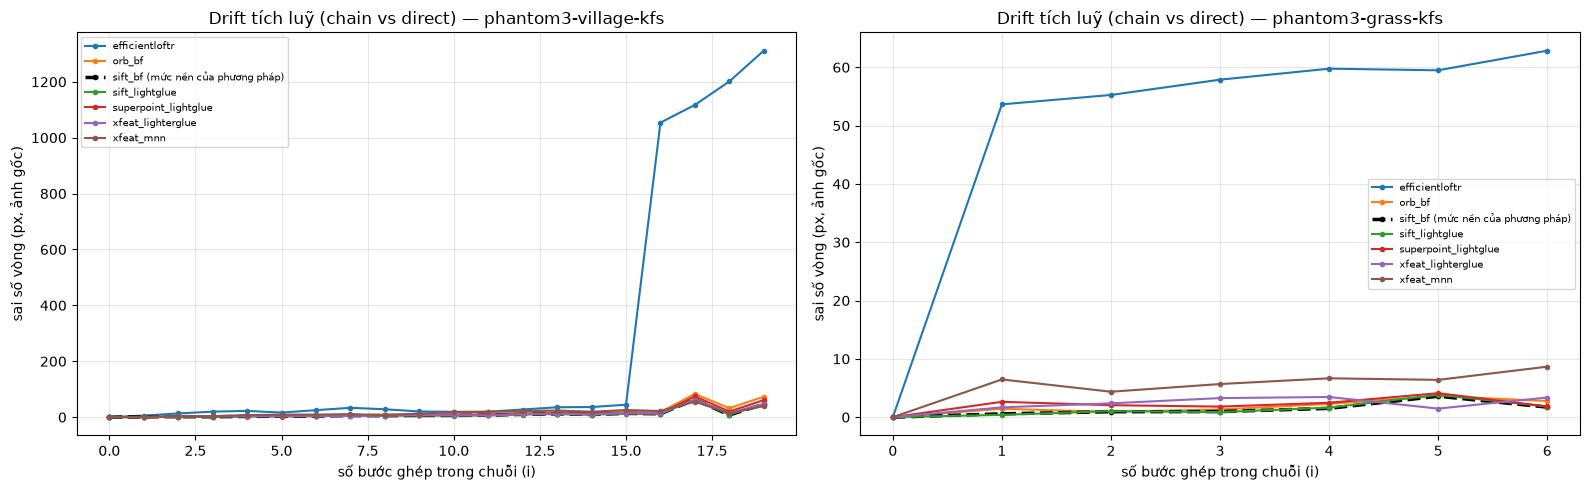

In [11]:
fig, axes = plt.subplots(1, len(SEQUENCES), figsize=(8 * len(SEQUENCES), 5))
for ax, sequence in zip(np.ravel(axes), SEQUENCES):
    for r in [x for x in results if x["sequence"] == sequence]:
        xs = [i for i, v in enumerate(r["series"]) if v is not None]
        ys = [v for v in r["series"] if v is not None]
        style = dict(lw=2.5, color="k", ls="--") if r["method"] == "sift_bf" else dict(lw=1.5)
        label = r["method"] + (" (mức nền của phương pháp)" if r["method"] == "sift_bf" else "")
        ax.plot(xs, ys, marker="o", ms=3, label=label, **style)
    ax.set_title(f"Drift tích luỹ (chain vs direct) — {sequence}")
    ax.set_xlabel("số bước ghép trong chuỗi (i)")
    ax.set_ylabel("sai số vòng (px, ảnh gốc)")
    ax.legend(fontsize=7); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 10. Kiểm chứng & lưu kết quả

Assert dưới đây bảo đảm: metric chạy đủ 7 mô hình × 2 sequence; drift tại $i=0$ phải bằng 0 (mốc tự so với chính nó); **mức nền `sift_bf` nhỏ** (nếu chính SIFT cũng "drift" lớn thì metric đang đo sai chứ không phải đo mô hình); và `efficientloftr` — ca đã biết vỡ bản đồ — phải tệ hơn hẳn mức nền.

In [12]:
assert len(results) == len(METHODS) * len(SEQUENCES), len(results)

# 1. Mốc: i = 0 thì chuỗi và ghép thẳng là cùng một ảnh -> drift phải đúng 0
for r in results:
    assert r["series"][0] == 0.0, (r["sequence"], r["method"], r["series"][0])

# 2. Mức nền: chính SIFT không được "drift" lớn, nếu không metric vô nghĩa
baseline = {r["sequence"]: r["final_drift_px"] for r in results if r["method"] == "sift_bf"}
for sequence, value in baseline.items():
    assert value < 60, (sequence, value)

# 3. Ca đã biết là vỡ bản đồ phải tệ hơn hẳn mức nền
for sequence in SEQUENCES:
    eloftr = next(r for r in results if r["sequence"] == sequence and r["method"] == "efficientloftr")
    assert eloftr["final_drift_px"] > 5 * baseline[sequence], (sequence, eloftr["final_drift_px"], baseline[sequence])

# 4. Ngưỡng hợp lệ được tôn trọng: mọi điểm đo đều có >= MIN_INLIERS inlier
for r in results:
    for entry, value in zip(r["inliers"], r["series"]):
        if value is not None and entry["i"] > 0:
            assert entry["inliers"] is not None and entry["inliers"] >= MIN_INLIERS, (r["method"], entry)

print("PASS: đủ 7 mô hình × 2 sequence, drift(i=0)=0, mức nền SIFT nhỏ, efficientloftr vượt trội")
for sequence, value in baseline.items():
    print(f"  mức nền {sequence}: {value:.1f} px")

report = {
    "scope": "drift tự nhất quán (chain vs direct) theo RDR-0007; đơn vị PIXEL ảnh gốc",
    "metric_decision": "docs/decisions/RDR-0007_drift_metric_choice.md",
    "run_used": run_dir.name,
    "reference_matcher": {"detector": "SIFT (OpenCV)", "nfeatures": 4000, "ratio": 0.75,
                          "ransac_px": 3.0, "min_inliers": MIN_INLIERS},
    "marker_points": "4 góc + tâm ảnh",
    "direction": "cả hai H đều ánh xạ frame i -> frame 0 (kiểm bằng assert drift(i=0) == 0)",
    "environment": {"numpy": np.__version__, "opencv": cv2.__version__},
    "input_hashes": {str(f.relative_to(ROOT)): hashlib.sha256(f.read_bytes()).hexdigest()
                     for s in SEQUENCES for f in (ROOT / "data" / s / "config.cfg",)},
    "caveats": [
        "mức nền = sai số của matcher tham chiếu, không tách rời khỏi sai số chuỗi",
        "chỉ đo được khi hai frame còn đủ vùng chồng (ngưỡng inlier)",
        "đơn vị pixel; quy đổi mét kế thừa giả định của cầu nối trajectory",
    ],
    "results": [{k: v for k, v in r.items() if k != "inliers"} for r in results],
}
target = ROOT / "notebooks" / "outputs" / "04_drift_evaluation" / "drift_selfconsistent.json"
target.parent.mkdir(parents=True, exist_ok=True)
target.write_text(json.dumps(report, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print("Đã lưu:", target)

PASS: đủ 7 mô hình × 2 sequence, drift(i=0)=0, mức nền SIFT nhỏ, efficientloftr vượt trội
  mức nền phantom3-village-kfs: 46.7 px
  mức nền phantom3-grass-kfs: 1.7 px
Đã lưu: d:\fptu\_hoc-lieu\ky4\cvprj\notebooks\outputs\04_drift_evaluation\drift_selfconsistent.json
